# Baseline A: Measurement-Only Glaucoma Classifier

Question, metrics and protocol: `docs/baseline_a.md`. This notebook is the driver; heavy logic lives in `src/glaucoma_project/`.

## 0. Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import joblib
import torch
import yaml

from glaucoma_project import REPO_ROOT
from glaucoma_project.classification import ablation, run_baseline
from glaucoma_project.data import SPLITS, SegmentationDataset
from glaucoma_project.evaluation.metrics import agreement, dice
from glaucoma_project.final_evaluation import run_final_evaluation
from glaucoma_project.freeze import freeze
from glaucoma_project.measurements.extract import measure_split
from glaucoma_project.segmentation.predict import load_model, predict_dataset
from glaucoma_project.runtime import pick_device
from glaucoma_project.visualization import plot_history, plot_roc, show_comparison, show_overlays

SEG_RUN = REPO_ROOT / 'runs' / 'segmentation' / 'unet_resnet34'
MEAS_DIR = REPO_ROOT / 'runs' / 'measurements'
CLF_DIR = REPO_ROOT / 'runs' / 'classification'
config = yaml.safe_load((REPO_ROOT / 'configs' / 'baseline_a.yaml').read_text())
datasets = {split: SegmentationDataset(split) for split in SPLITS}
{split: len(ds) for split, ds in datasets.items()}

/Users/md.khan/Documents/code/glaucoma-prediction/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{'train': 787, 'validation': 200, 'in_domain_test': 327, 'external_test': 486}

## 1. Data check
Expert disc (cyan) and cup (yellow) outlines drawn over a few training images per camera, and over PAPILA, the external dataset. We check that the outlines sit on the real disc and cup, and see how the cameras differ.

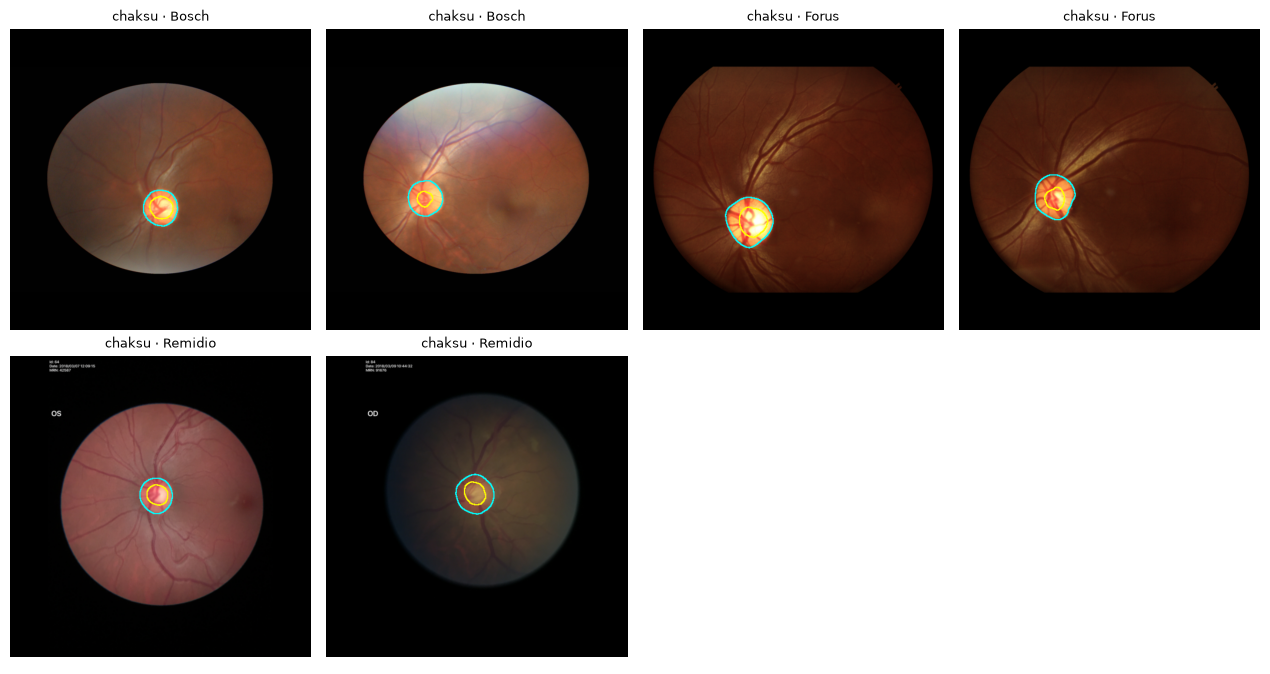

In [2]:
train = datasets['train'].table
indices = train.groupby('camera').head(2).index.tolist()
show_overlays(datasets['train'], indices);

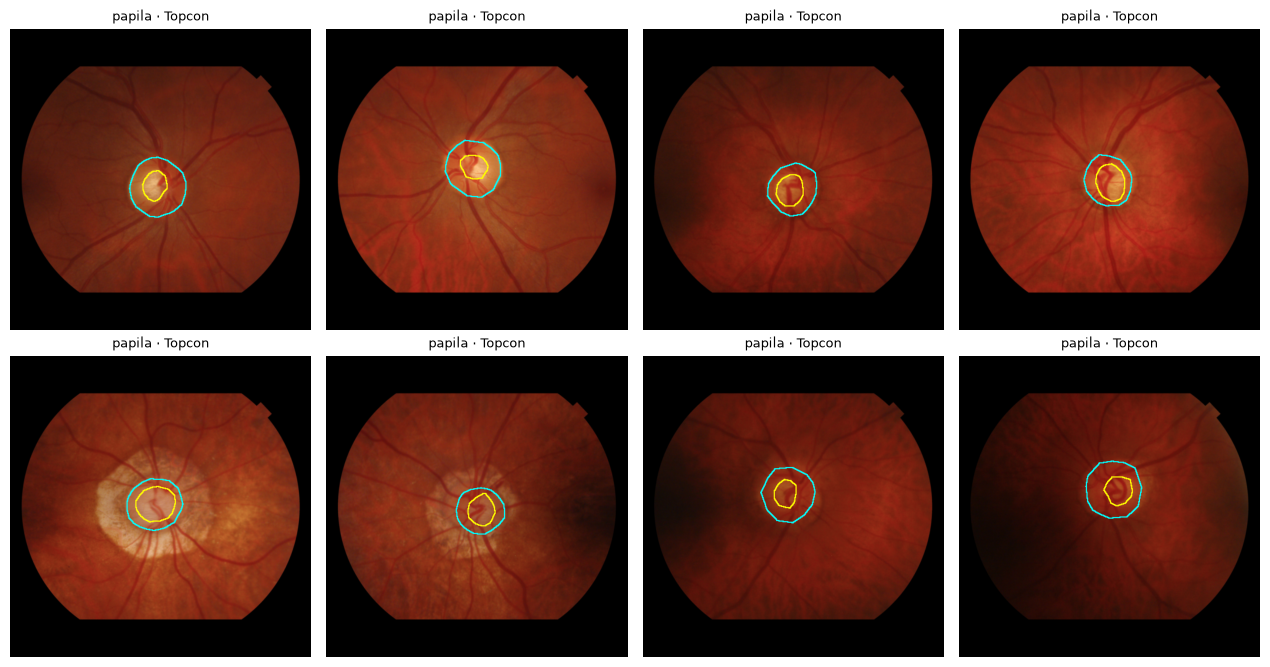

In [3]:
external = datasets['external_test']
show_overlays(external, list(range(0, 8)), ncols=4);

In [4]:
item = datasets['train'][0]
print({k: tuple(v.shape) if hasattr(v, 'shape') else v for k, v in item.items()})

{'image': (3, 512, 512), 'mask': (2, 512, 512), 'image_id': 'chaksu_Bosch_train_Image101'}


## 2. Segmentation
A U-Net with a pretrained ResNet34 encoder, trained on the training split (`configs/segmentation.yaml`, run with `python -m glaucoma_project.segmentation.train`). The checkpoint with the best validation Dice is kept. Dice is the overlap between predicted and expert outline (1 = identical).

best epoch 25: validation Dice disc 0.975, cup 0.919


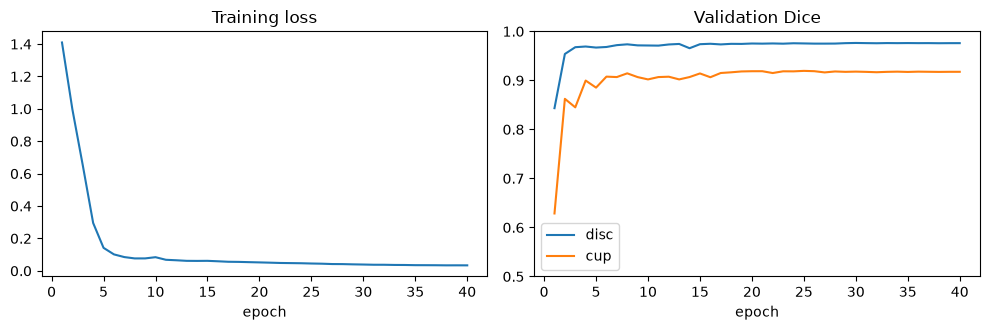

In [5]:
history = pd.read_csv(SEG_RUN / 'history.csv')
plot_history(history)
best = history.loc[(history.val_dice_disc + history.val_dice_cup).idxmax()]
print(f"best epoch {int(best.epoch)}: validation Dice disc {best.val_dice_disc:.3f}, cup {best.val_dice_cup:.3f}")

Per-image Dice on the validation split, by camera, and the worst cases next to the expert outlines.

In [6]:
model = load_model(SEG_RUN, device=pick_device())
validation = datasets['validation']
predicted = predict_dataset(model, validation)
expert = torch.stack([validation[i]['mask'] for i in range(len(validation))])
scores = dice(predicted, expert)

per_image = validation.table[['image_id', 'camera']].assign(disc=scores[:, 0], cup=scores[:, 1])
per_image.groupby('camera')[['disc', 'cup']].agg(['mean', 'min']).round(3)

disc           cup       
          mean    min   mean    min
camera                             
Bosch    0.977  0.936  0.925  0.888
Forus    0.980  0.970  0.905  0.804
Remidio  0.975  0.914  0.920  0.563

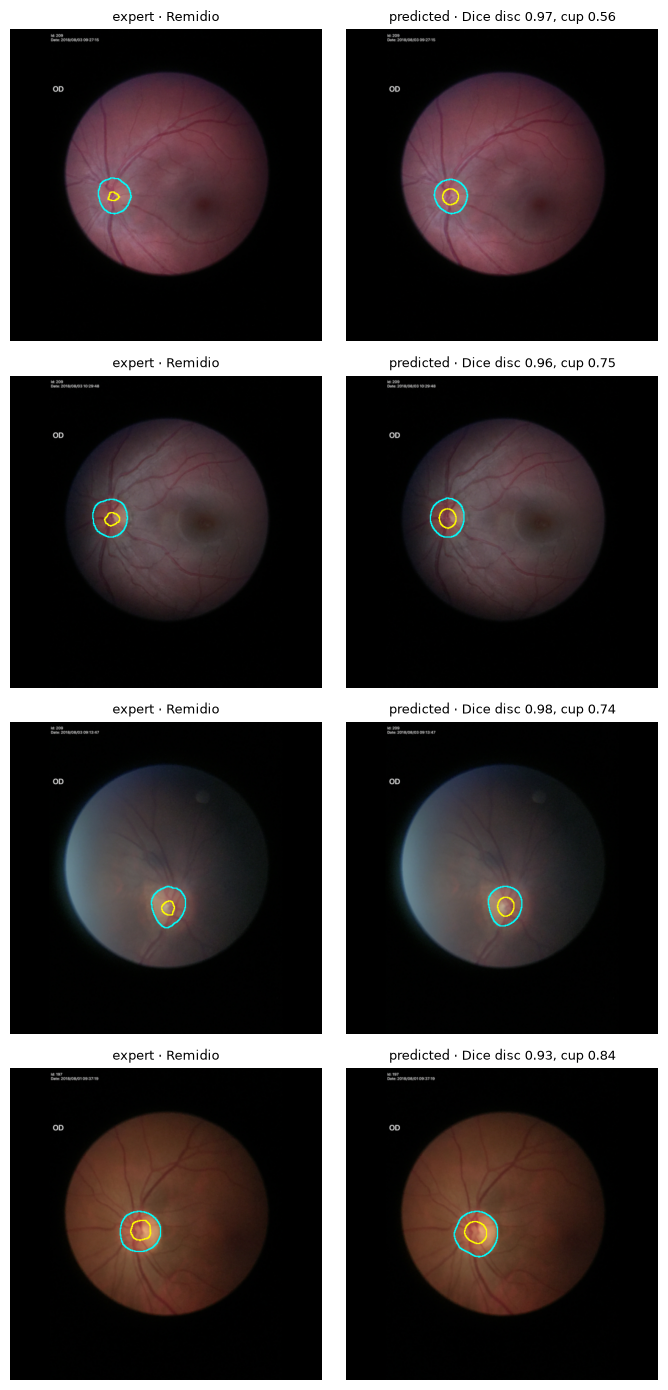

In [7]:
worst = scores.mean(dim=1).argsort()[:4].tolist()
show_comparison(validation, predicted, worst, scores.numpy());

## 3. Measurements
Vertical, horizontal and area cup-to-disc ratio (CDR) plus disc and cup area, computed from the **predicted** masks (Baseline A input) and from the **expert** masks (the "oracle", a best case that shows what segmentation error costs). Areas are in pixels. Only train and validation are measured here; the test splits are measured once, at the end.

In [8]:
MEAS_DIR.mkdir(parents=True, exist_ok=True)
measurements = pd.concat([measure_split(split, source, model)
                          for split in ['train', 'validation'] for source in ['predicted', 'expert']])
measurements.to_csv(MEAS_DIR / 'measurements_dev.csv', index=False)
measurements.groupby(['split', 'source']).size().unstack()

source,expert,predicted
split,,
train,787,787
validation,200,200


How close are the predicted measurements to the expert ones (validation)?

In [9]:
val = measurements[measurements.split == 'validation']
by_source = {s: val[val.source == s].set_index('image_id') for s in ['predicted', 'expert']}
pd.DataFrame({m: agreement(by_source['predicted'][m], by_source['expert'][m])
              for m in ['vcdr', 'hcdr', 'area_cdr']}).T.round(3)

,mae,pearson,n
vcdr,0.035,0.776,200.0
hcdr,0.034,0.788,200.0
area_cdr,0.031,0.853,200.0


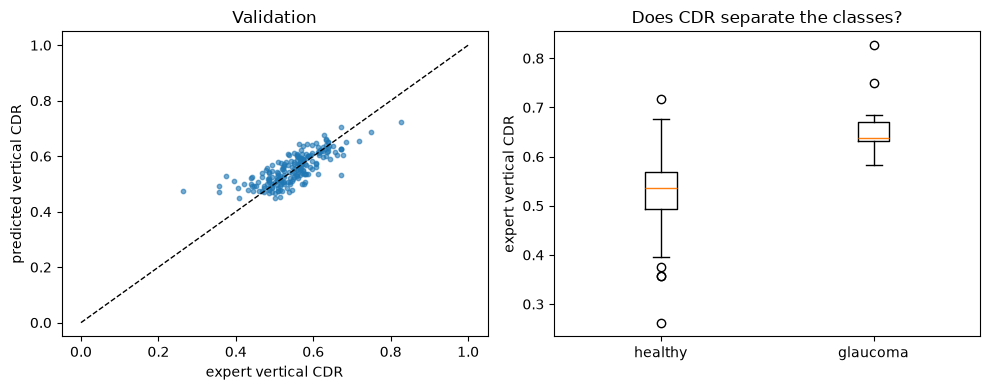

In [10]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 4))
left.scatter(by_source['expert'].vcdr, by_source['predicted'].vcdr, s=10, alpha=0.6)
left.plot([0, 1], [0, 1], 'k--', lw=1)
left.set(xlabel='expert vertical CDR', ylabel='predicted vertical CDR', title='Validation')
labelled = by_source['expert'].dropna(subset=['binary_label'])
right.boxplot([labelled[labelled.binary_label == k].vcdr for k in (0, 1)], tick_labels=['healthy', 'glaucoma'])
right.set(ylabel='expert vertical CDR', title='Does CDR separate the classes?')
fig.tight_layout();

## 4. Classification
Logistic regression on the three cup-to-disc ratios (areas depend on the camera's field of view, so they are left out; an ablation below checks this). All development images (train and validation) are used, since validation alone has only 27 glaucoma cases. The regularisation strength C is chosen by 5-fold cross-validation with duplicate groups kept together, and the decision threshold is Youden's J on the out-of-fold scores. The same steps run on expert-mask measurements, the oracle.

In [11]:
results = {source: run_baseline(measurements, source, config) for source in ['predicted', 'expert']}
pd.DataFrame({source: {'C': r.best_c, 'threshold': round(r.threshold, 3)} for source, r in results.items()})

,predicted,expert
C,0.10,100.000
threshold,0.54,0.386


Development performance from out-of-fold predictions (every image is scored by a model that did not see it), with 95% bootstrap confidence intervals.

In [12]:
for source, r in results.items():
    print(f'{source} masks'); display(r.development.round(3))

predicted masks


,value,ci_low,ci_high
auc,0.960,0.945,0.973
sensitivity,0.909,0.857,0.957
specificity,0.877,0.855,0.899
sensitivity_at_95_specificity,0.705,0.626,0.839
auprc,0.831,0.773,0.881
balanced_accuracy,0.893,0.866,0.919


expert masks


,value,ci_low,ci_high
auc,0.980,0.972,0.986
sensitivity,0.985,0.959,1.000
specificity,0.902,0.881,0.922
sensitivity_at_95_specificity,0.841,0.763,0.928
auprc,0.876,0.820,0.919
balanced_accuracy,0.943,0.927,0.957


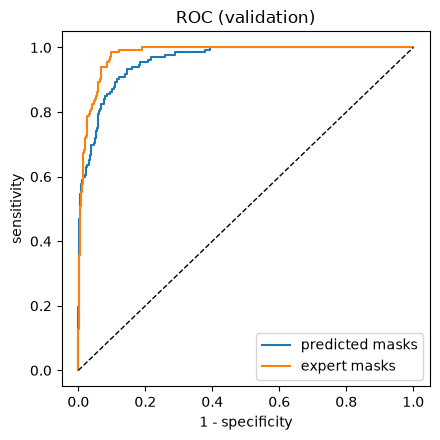

In [13]:
plot_roc({f'{source} masks': (r.labels, r.out_of_fold_score) for source, r in results.items()});

Ablation, on cross-validated AUC. Do the areas, or a non-linear model, help over the plain baseline?

In [14]:
pd.DataFrame({source: ablation(measurements, source, config, results[source].best_c)
              for source in results}).round(3)

,predicted,expert
logistic regression (ratios),0.961,0.981
logistic regression (ratios + areas),0.962,0.981
gradient boosting (ratios),0.952,0.974


### Freeze
Save the fitted classifiers and record the code version and the hash of every frozen file in `docs/frozen_baseline_a.json`. This is done once, before the test sets are touched. Commit `src/` and `configs/` first.

In [15]:
CLF_DIR.mkdir(parents=True, exist_ok=True)
for source, r in results.items():
    joblib.dump({'model': r.model, 'threshold': r.threshold, 'features': config['features']},
                CLF_DIR / f'baseline_a_{source}.joblib')
frozen_files = {'segmentation_weights': SEG_RUN / 'best.pt',
                'classifier_predicted': CLF_DIR / 'baseline_a_predicted.joblib',
                'classifier_expert': CLF_DIR / 'baseline_a_expert.joblib'}
freeze(frozen_files, {'features': config['features'], 'thresholds': {s: r.threshold for s, r in results.items()},
                      'c': {s: r.best_c for s, r in results.items()}})

{'git_commit': '1bcfae590095d167dcfe82527afff97affd047b3',
 'files': {'segmentation_weights': {'path': 'runs/segmentation/unet_resnet34/best.pt',
   'sha256': '4f2fd3aa280c3193170444543b5b6acad3d46e3c93693aaee7ffb3ef45c241a3'},
  'classifier_predicted': {'path': 'runs/classification/baseline_a_predicted.joblib',
   'sha256': 'ce3e1f7dd5e9138ad1f84725e7e8df3a7381a4d8a96d83bbaf1a52df396d6fb8'},
  'classifier_expert': {'path': 'runs/classification/baseline_a_expert.joblib',
   'sha256': 'c2380d7432334df1bd59c0c49a1ea6cc9e615223f63b7823352dc7db718421fa'}},
 'settings': {'features': ['vcdr', 'hcdr', 'area_cdr'],
  'thresholds': {'predicted': 0.5402919049456609,
   'expert': 0.38569585192007777},
  'c': {'predicted': 0.1, 'expert': 100.0}}}

## 5. Final evaluation
Run **once**: the frozen pipeline on the CHAKSU test set and PAPILA. The code checks that nothing changed since the freeze and refuses to run twice. Rules for reporting are in `docs/baseline_a.md`.

In [15]:
final = run_final_evaluation(config)
final['segmentation'].round(3)

,split,dice_disc,dice_cup,vcdr_mae,vcdr_pearson,hcdr_mae,hcdr_pearson,area_cdr_mae,area_cdr_pearson
0,in_domain_test,0.976,0.916,0.036,0.750,0.036,0.735,0.035,0.805
1,external_test,0.836,0.472,0.192,0.338,0.206,0.306,0.156,0.477


In [16]:
table = final['classification']
table[table.analysis == 'main'].pivot_table(index=['split', 'source', 'n', 'positives'], columns='metric', values='value').round(3)

metric                                               auc  auprc  \
split          source               n   positives                 
external_test  expert               418 85         0.799  0.668   
               predicted            418 85         0.718  0.559   
               vcdr only (no model) 404 79         0.722    NaN   
in_domain_test expert               327 50         0.984  0.928   
               predicted            327 50         0.934  0.829   
               vcdr only (no model) 327 50         0.937    NaN   

metric                                             balanced_accuracy  \
split          source               n   positives                      
external_test  expert               418 85                     0.654   
               predicted            418 85                     0.671   
               vcdr only (no model) 404 79                       NaN   
in_domain_test expert               327 50                     0.949   
               predicted            327 50                     0.847   
               vcdr only (no model) 327 50                       NaN   

metric                                             sensitivity  \
split          source               n   positives                
external_test  expert               418 85               0.318   
               predicted            418 85               0.400   
               vcdr only (no model) 404 79                 NaN   
in_domain_test expert               327 50               1.000   
               predicted            327 50               0.780   
               vcdr only (no model) 327 50                 NaN   

metric                                             sensitivity_at_95_specificity  \
split          source               n   positives                                  
external_test  expert               418 85                                 0.529   
               predicted            418 85                                 0.400   
               vcdr only (no model) 404 79                                   NaN   
in_domain_test expert               327 50                                 0.800   
               predicted            327 50                                 0.740   
               vcdr only (no model) 327 50                                   NaN   

metric                                             specificity  
split          source               n   positives               
external_test  expert               418 85               0.991  
               predicted            418 85               0.943  
               vcdr only (no model) 404 79                 NaN  
in_domain_test expert               327 50               0.899  
               predicted            327 50               0.913  
               vcdr only (no model) 327 50                 NaN

## 6. Post-hoc: why PAPILA failed
Written after seeing the test results, to explain them. Nothing here changes the frozen result. Labels are used only to describe the data.

In [2]:
test = pd.read_csv(REPO_ROOT / 'runs' / 'final' / 'measurements_test.csv')
dev = pd.read_csv(MEAS_DIR / 'measurements_dev.csv')
both = pd.concat([dev[dev.split == 'validation'], test])
both['dataset'] = both.split.map({'external_test': 'PAPILA'}).fillna('CHAKSU')
both.groupby(['dataset', 'source'])[['vcdr', 'area_cdr', 'disc_area', 'cup_area']].mean().round(2)

vcdr  area_cdr  disc_area  cup_area
dataset source                                        
CHAKSU  expert     0.55      0.32    3725.92   1226.76
        predicted  0.55      0.32    3708.44   1224.61
PAPILA  expert     0.36      0.15    6849.10   1049.04
        predicted  0.51      0.28    6531.96   1978.17

Average expert vertical CDR by label. PAPILA's healthy eyes already have smaller cups than CHAKSU's, and its glaucoma eyes sit below CHAKSU's healthy average.

In [3]:
expert = both[(both.source == 'expert') & both.binary_label.notna()]
expert.groupby(['dataset', 'binary_label']).vcdr.agg(['mean', 'std', 'count']).round(2)

mean   std  count
dataset binary_label                   
CHAKSU  0.0           0.53  0.05    450
        1.0           0.67  0.06     77
PAPILA  0.0           0.32  0.12    333
        1.0           0.52  0.19     85

Expert (left) and predicted (right) outlines on four random PAPILA images. The model draws cups the way CHAKSU's experts did, which is larger than PAPILA's, and sometimes finds nothing.

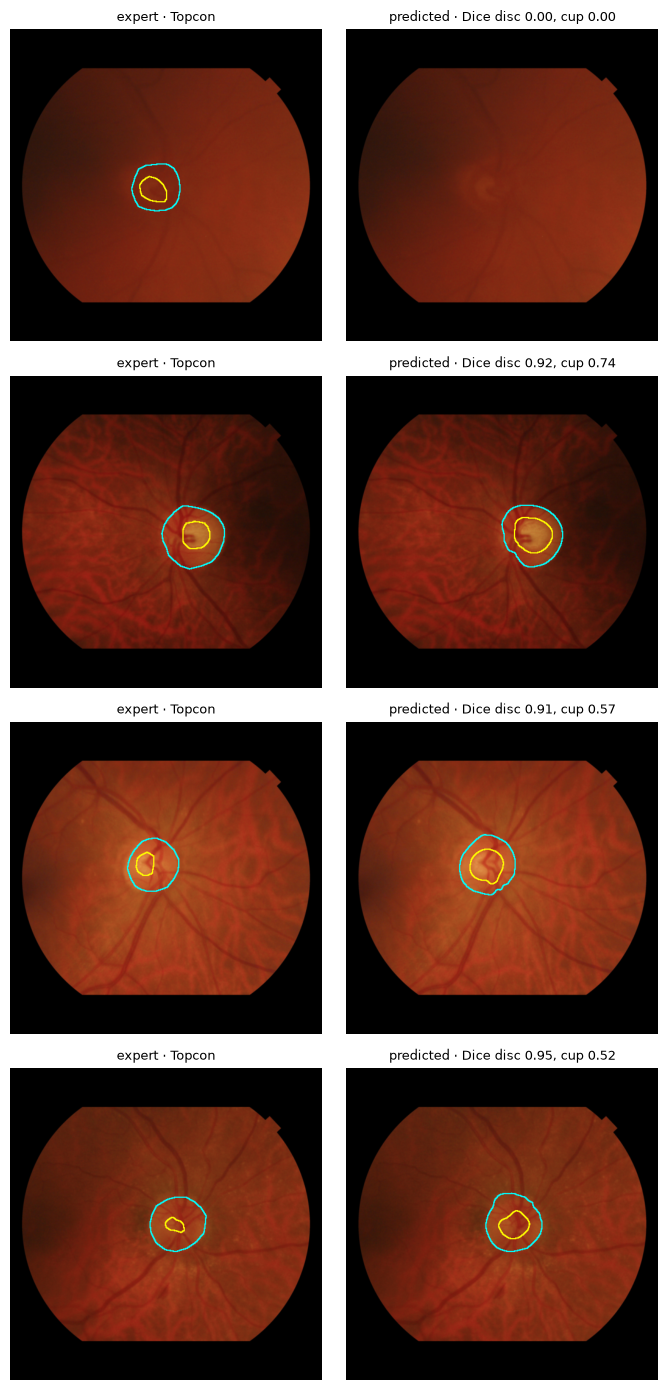

In [4]:
seg_model = load_model(SEG_RUN, device=pick_device())
papila = datasets['external_test']
papila_pred = predict_dataset(seg_model, papila)
papila_truth = torch.stack([papila[i]['mask'] for i in range(len(papila))])
sample = np.random.default_rng(0).choice(len(papila), 4, replace=False).tolist()
show_comparison(papila, papila_pred, sample, dice(papila_pred, papila_truth).numpy());

## 7. Results and limitations
See `docs/baseline_a.md`.